# Electricity Theft and Abnormal Consumption Detection

**Goal:** classify electricity consumers as *normal* or *theft / abnormal* from their smart-meter daily consumption history.

### 1. Problem statement and objectives
Electricity theft (meter bypass, tampering, intermittent interference) causes large non-technical losses for utilities. Smart meters give daily kWh readings, which can reveal theft through level drops, zero-reading gaps, and abnormal spikes.

**Objectives**
1. Build a labelled consumer-level dataset and engineer features that capture theft signatures.
2. Implement and compare **at least three** ML algorithms (we use five, plus an unsupervised baseline).
3. Evaluate with stratified cross-validation and a held-out test set, using imbalance-aware metrics.
4. Analyse errors by theft type and interpret which features drive predictions.
5. Deliver a small working prototype that scores new consumers.

> **Data note:** the dataset is synthetic (generated by `src/generate_dataset.py`) because real utility smart-meter data is confidential. Theft patterns are simulated as bypass (level drop), intermittent zeros, and spike-then-drop. Results should be read as a methodology demonstration; real deployment needs validation on utility data.

In [1]:
import sys, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_fscore_support, accuracy_score, average_precision_score)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
np.random.seed(42)

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from features import FEATURE_COLUMNS, build_feature_table
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /home/claude/electricity_theft_detection


### 2. Data loading and exploratory data analysis (EDA)

In [2]:
readings = pd.read_csv(ROOT / "data/raw/daily_consumption.csv", parse_dates=["date"])
labels = pd.read_csv(ROOT / "data/raw/consumer_labels.csv")
print("Readings:", readings.shape, "| consumers:", readings.consumer_id.nunique())
print("Missing values:", int(readings.isna().sum().sum()))
print("Date range:", readings.date.min().date(), "to", readings.date.max().date())
readings.describe()

Readings: (365000, 3) | consumers: 1000
Missing values: 0
Date range: 2025-01-01 to 2025-12-31


,date,kwh
count,365000,365000.000000
mean,2025-07-02 00:00:00,12.013700
min,2025-01-01 00:00:00,0.140000
25%,2025-04-02 00:00:00,6.910000
50%,2025-07-02 00:00:00,10.190000
75%,2025-10-01 00:00:00,15.060000
max,2025-12-31 00:00:00,168.520000
std,NaN,7.531713


theft_type
none            850
intermittent     58
bypass           48
spike_drop       44
Name: count, dtype: int64

Theft prevalence: 15.0%


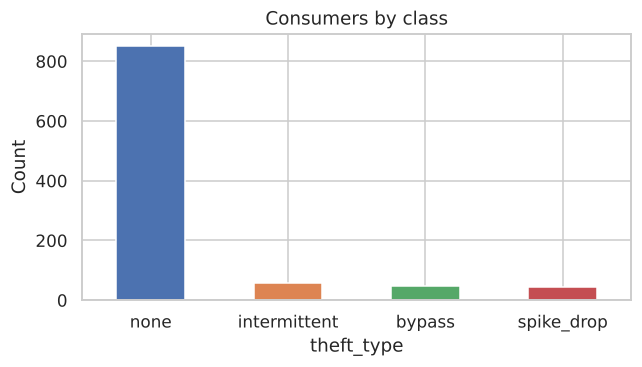

In [3]:
print(labels.theft_type.value_counts())
print("\nTheft prevalence: {:.1%}".format(labels.is_theft.mean()))
fig, ax = plt.subplots(figsize=(6, 3.5))
labels.theft_type.value_counts().plot.bar(ax=ax, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
ax.set_title("Consumers by class"); ax.set_ylabel("Count"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG / "class_distribution.png"); plt.show()

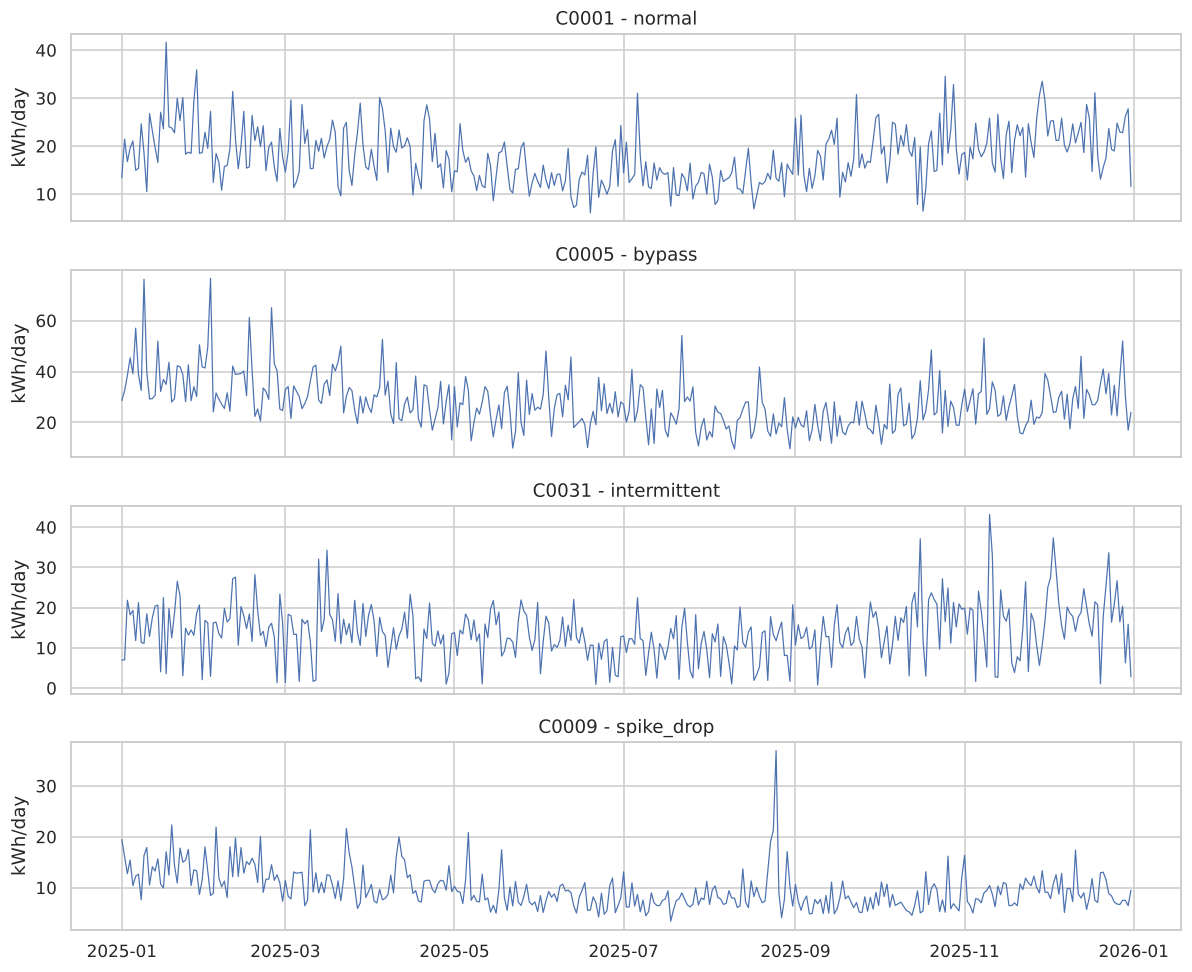

In [4]:
# Example daily series: one normal consumer vs one of each theft type
examples = {"normal": labels[labels.theft_type == "none"].consumer_id.iloc[0]}
for t in ["bypass", "intermittent", "spike_drop"]:
    examples[t] = labels[labels.theft_type == t].consumer_id.iloc[0]

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, (name, cid) in zip(axes, examples.items()):
    s = readings[readings.consumer_id == cid]
    ax.plot(s.date, s.kwh, lw=0.8, color="#4C72B0")
    ax.set_title(f"{cid} - {name}"); ax.set_ylabel("kWh/day")
plt.tight_layout(); plt.savefig(FIG / "example_consumption_profiles.png"); plt.show()

### 3. Feature engineering
Feature computation lives in `src/features.py`, so the notebook, the prototype, and any new data use identical logic. The precomputed table is loaded here, and the first rows are checked against a fresh computation to confirm consistency.

In [5]:
features = pd.read_csv(ROOT / "data/processed/consumer_features.csv")
check = build_feature_table(readings)
assert np.allclose(features[FEATURE_COLUMNS].values, check[FEATURE_COLUMNS].values), "feature mismatch"
data = features.merge(labels, on="consumer_id")
print("Feature matrix:", data.shape, "| features:", len(FEATURE_COLUMNS))
data[FEATURE_COLUMNS].describe().T[["mean", "std", "min", "max"]].round(3)

Feature matrix: (1000, 18) | features: 15


,mean,std,min,max
mean_kwh,12.014,5.699,3.108,45.616
median_kwh,11.340,5.401,2.900,43.960
std_kwh,4.434,2.167,1.120,15.345
cv,0.369,0.045,0.296,0.566
zero_ratio,0.001,0.005,0.000,0.033
longest_zero_run,0.067,0.277,0.000,2.000
level_change,1.001,0.138,0.537,1.654
quarter_change,1.006,0.178,0.486,1.943
spike_ratio,0.048,0.026,0.014,0.203
drop_ratio,0.048,0.026,0.016,0.190


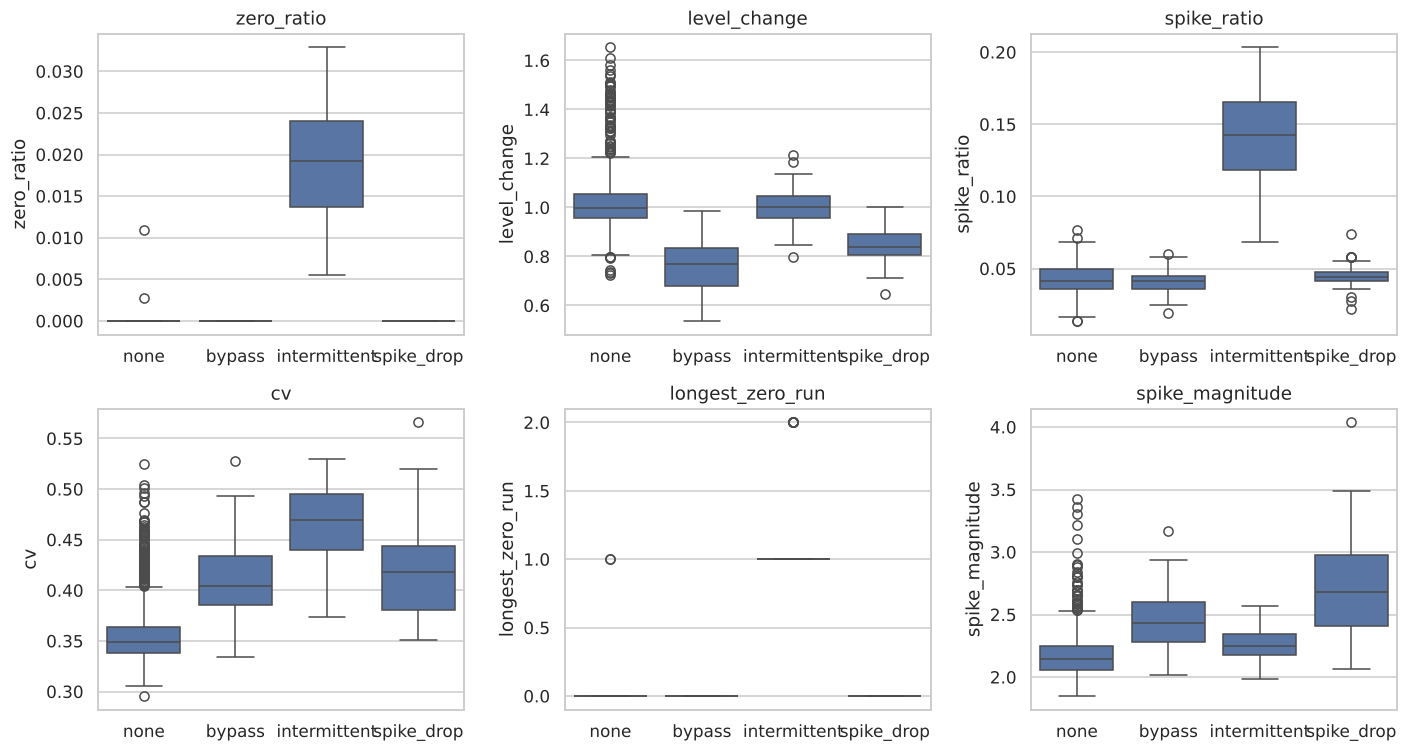

In [6]:
# How features separate the classes
show = ["zero_ratio", "level_change", "spike_ratio", "cv", "longest_zero_run", "spike_magnitude"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), show):
    sns.boxplot(data=data, x="theft_type", y=col, ax=ax, order=["none", "bypass", "intermittent", "spike_drop"])
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "feature_by_class.png"); plt.show()

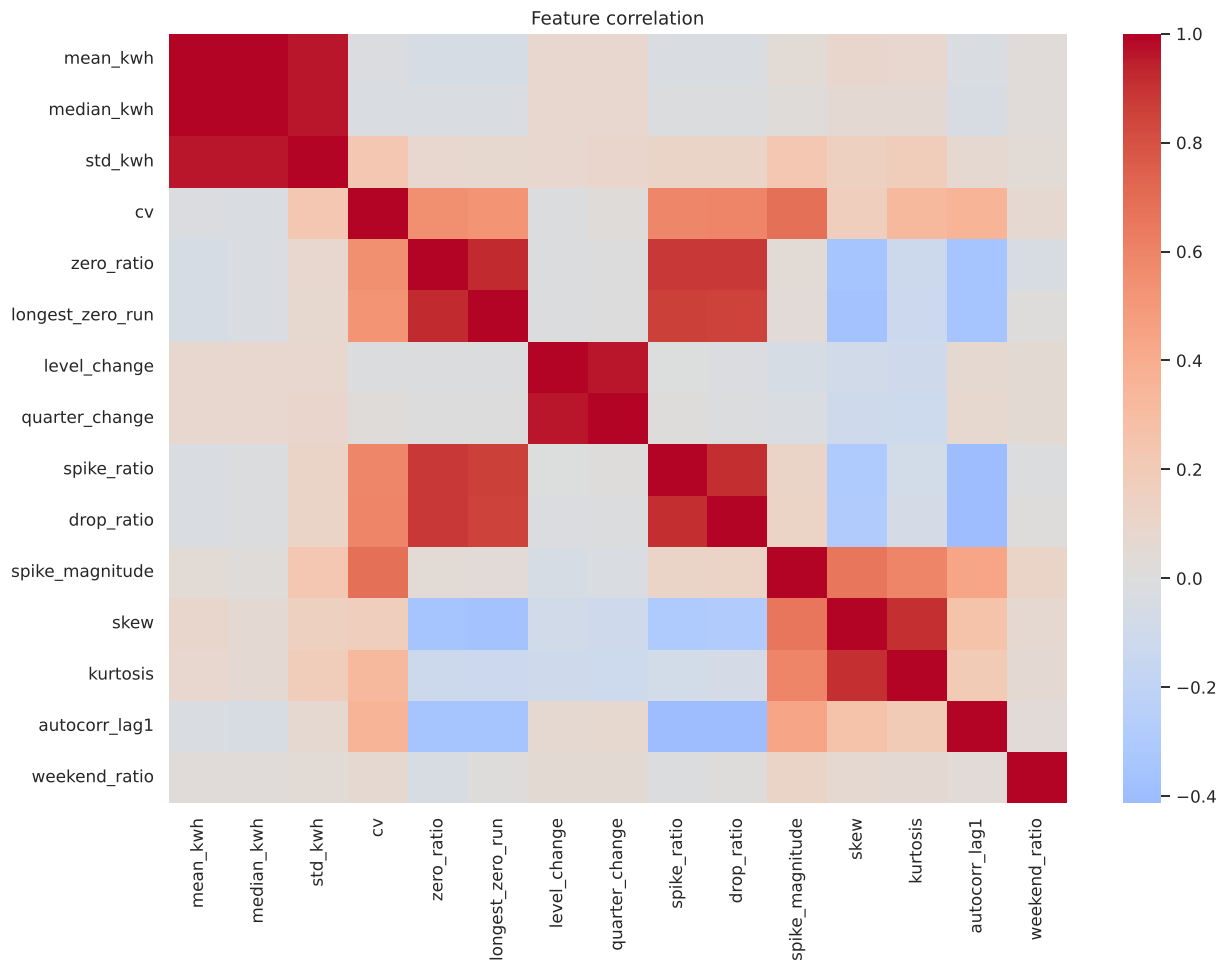

In [7]:
plt.figure(figsize=(12, 9))
corr = data[FEATURE_COLUMNS].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Feature correlation"); plt.tight_layout(); plt.savefig(FIG / "feature_correlation.png"); plt.show()

### 4. Preprocessing and train/test split
- Stratified 80/20 split so the ~15% theft rate is kept in both sets.
- Features are standardised inside each pipeline, fitted on training data only, which avoids leakage.
- Class imbalance is handled with `class_weight="balanced"` where the model supports it.

In [8]:
X = data[FEATURE_COLUMNS].values
y = data["is_theft"].values
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "theft rate {:.3f}".format(y_train.mean()))
print("Test: ", X_test.shape, "theft rate {:.3f}".format(y_test.mean()))

Train: (800, 15) theft rate 0.150
Test:  (200, 15) theft rate 0.150


### 5. Model implementation
Five supervised models, plus an unsupervised Isolation Forest as a baseline that never sees labels:
1. **Logistic Regression** - linear, interpretable baseline
2. **Random Forest** - bagged decision trees
3. **Gradient Boosting** - sequential boosted trees
4. **Support Vector Machine (RBF)** - kernel margin classifier
5. **K-Nearest Neighbours** - distance-based, non-parametric
6. **Isolation Forest** (unsupervised) - anomaly score, no labels used

In [9]:
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": make_pipeline(StandardScaler(),
        RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                               random_state=42, n_jobs=-1)),
    "Gradient Boosting": make_pipeline(StandardScaler(),
        GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42)),
    "SVM (RBF)": make_pipeline(StandardScaler(),
        SVC(kernel="rbf", C=2.0, gamma="scale", probability=True, class_weight="balanced", random_state=42)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights="distance")),
}
print("Supervised models:", list(models))

Supervised models: ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'SVM (RBF)', 'KNN']


### 6. Evaluation
**Primary metrics** are for the theft class, since accuracy alone is misleading with ~15% prevalence:
- **Precision** - of flagged consumers, the share that really are thieves (controls wasted inspections)
- **Recall** - share of thieves caught (controls missed losses)
- **F1** - harmonic mean of the two
- **ROC-AUC / PR-AUC** - threshold-independent ranking quality

We report 5-fold stratified cross-validation on the training set, then a single run on the untouched test set.

In [10]:
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
        row[m + "_std"] = res[f"test_{m}"].std()
    cv_rows.append(row)
cv_df = pd.DataFrame(cv_rows).set_index("model")
cv_df[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].round(3).sort_values("f1", ascending=False)

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
SVM (RBF),0.954,0.807,0.908,0.855,0.981,0.892
Logistic Regression,0.952,0.797,0.925,0.854,0.985,0.940
Random Forest,0.959,0.931,0.783,0.847,0.982,0.944
Gradient Boosting,0.954,0.869,0.817,0.838,0.977,0.928
KNN,0.952,0.886,0.783,0.831,0.955,0.907


In [11]:
# Unsupervised baseline: Isolation Forest flags outliers without using labels
iso = make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, contamination=0.15, random_state=42))
iso.fit(X_train)                       # trained on features only (no y)
iso_pred_test = (iso.predict(X_test) == -1).astype(int)
iso_score_test = -iso.decision_function(X_test)   # higher = more anomalous
print("Isolation Forest test  precision {:.3f}  recall {:.3f}  F1 {:.3f}  ROC-AUC {:.3f}".format(
    precision_recall_fscore_support(y_test, iso_pred_test, average="binary", zero_division=0)[0],
    precision_recall_fscore_support(y_test, iso_pred_test, average="binary", zero_division=0)[1],
    precision_recall_fscore_support(y_test, iso_pred_test, average="binary", zero_division=0)[2],
    roc_auc_score(y_test, iso_score_test)))

Isolation Forest test  precision 0.655  recall 0.633  F1 0.644  ROC-AUC 0.892


In [12]:
# Fit every supervised model on the full training set and evaluate on the test set
test_rows, probas = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="binary", zero_division=0)
    probas[name] = proba
    test_rows.append({"model": name, "accuracy": accuracy_score(y_test, pred), "precision": p,
                      "recall": r, "f1": f, "roc_auc": roc_auc_score(y_test, proba),
                      "pr_auc": average_precision_score(y_test, proba)})
test_df = pd.DataFrame(test_rows).set_index("model")
test_df.loc["Isolation Forest (unsup.)"] = [accuracy_score(y_test, iso_pred_test),
    *precision_recall_fscore_support(y_test, iso_pred_test, average="binary", zero_division=0)[:3],
    roc_auc_score(y_test, iso_score_test), average_precision_score(y_test, iso_score_test)]
test_df = test_df.sort_values("f1", ascending=False)
test_df.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Gradient Boosting,0.960,0.844,0.900,0.871,0.987,0.949
Random Forest,0.960,0.867,0.867,0.867,0.980,0.921
KNN,0.955,0.862,0.833,0.847,0.967,0.910
SVM (RBF),0.945,0.771,0.900,0.831,0.982,0.922
Logistic Regression,0.920,0.659,0.967,0.784,0.977,0.865
Isolation Forest (unsup.),0.895,0.655,0.633,0.644,0.892,0.688


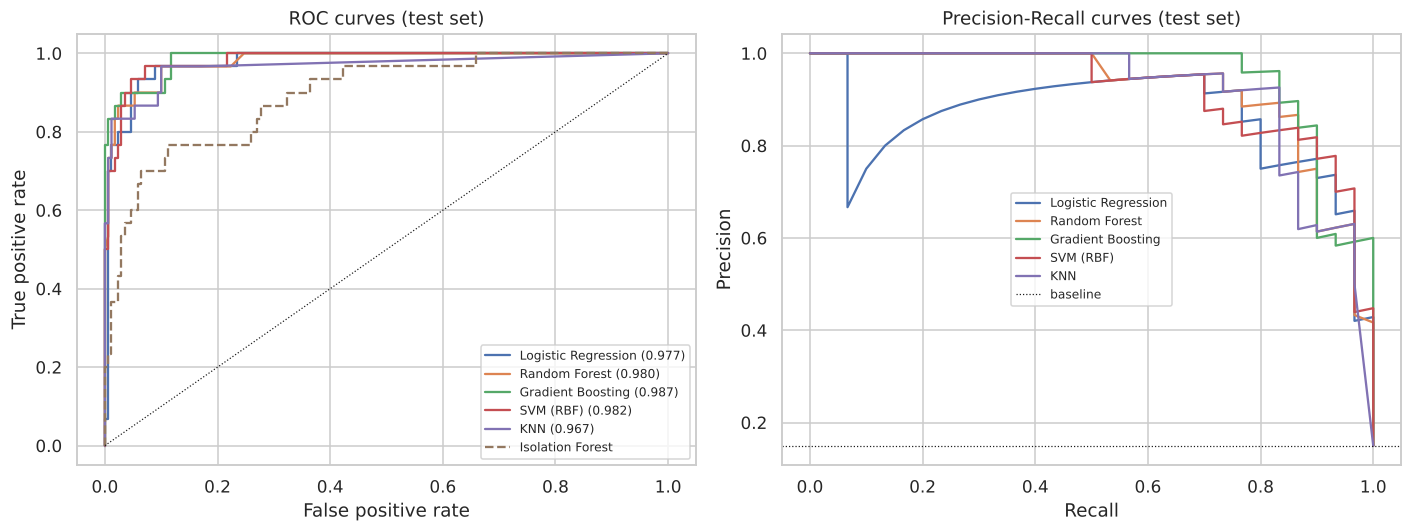

In [13]:
# ROC and Precision-Recall curves for all models
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba); a1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, proba):.3f})")
from sklearn.metrics import precision_recall_curve
for name, proba in probas.items():
    pr_p, pr_r, _ = precision_recall_curve(y_test, proba); a2.plot(pr_r, pr_p, label=name)
fpr, tpr, _ = roc_curve(y_test, iso_score_test); a1.plot(fpr, tpr, "--", label="Isolation Forest")
a1.plot([0, 1], [0, 1], "k:", lw=0.8); a1.set_xlabel("False positive rate"); a1.set_ylabel("True positive rate")
a1.set_title("ROC curves (test set)"); a1.legend(fontsize=8)
a2.axhline(y_test.mean(), color="k", ls=":", lw=0.8, label="baseline")
a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.set_title("Precision-Recall curves (test set)"); a2.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "roc_pr_curves.png"); plt.show()

Best model by F1: Gradient Boosting


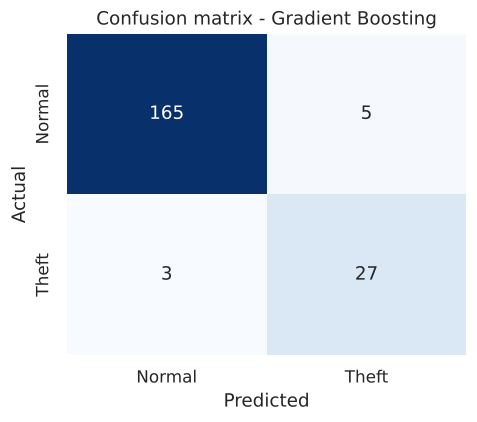

              precision    recall  f1-score   support

      Normal       0.98      0.97      0.98       170
       Theft       0.84      0.90      0.87        30

    accuracy                           0.96       200
   macro avg       0.91      0.94      0.92       200
weighted avg       0.96      0.96      0.96       200



In [14]:
# Confusion matrix of the best model (by F1 on test set)
best_name = test_df.drop("Isolation Forest (unsup.)").index[0]
print("Best model by F1:", best_name)
best_pred = (probas[best_name] >= 0.5).astype(int)
cm = confusion_matrix(y_test, best_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Normal", "Theft"], yticklabels=["Normal", "Theft"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix - {best_name}")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix_best.png"); plt.show()
print(classification_report(y_test, best_pred, target_names=["Normal", "Theft"], zero_division=0))

### 7. Hyperparameter tuning
We tune the Random Forest with a small grid search over 5-fold CV on the training set. The test set is not used during tuning.

In [15]:
param_grid = {
    "randomforestclassifier__n_estimators": [200, 400],
    "randomforestclassifier__max_depth": [None, 6, 10],
    "randomforestclassifier__min_samples_leaf": [1, 3],
}
rf_base = make_pipeline(StandardScaler(), RandomForestClassifier(class_weight="balanced_subsample",
                                                                  random_state=42, n_jobs=-1))
gs = GridSearchCV(rf_base, param_grid, scoring="f1", cv=cv, n_jobs=-1)
gs.fit(X_train, y_train)
print("Best params:", gs.best_params_)
print("Best CV F1: {:.3f}".format(gs.best_score_))
tuned = gs.best_estimator_
tuned_proba = tuned.predict_proba(X_test)[:, 1]
tp = (tuned_proba >= 0.5).astype(int)
print("Tuned RF on test -> F1 {:.3f} | ROC-AUC {:.3f} | PR-AUC {:.3f}".format(
    precision_recall_fscore_support(y_test, tp, average="binary", zero_division=0)[2],
    roc_auc_score(y_test, tuned_proba), average_precision_score(y_test, tuned_proba)))

Best params: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 3, 'randomforestclassifier__n_estimators': 400}
Best CV F1: 0.882
Tuned RF on test -> F1 0.857 | ROC-AUC 0.980 | PR-AUC 0.929


### 8. Feature importance and interpretation

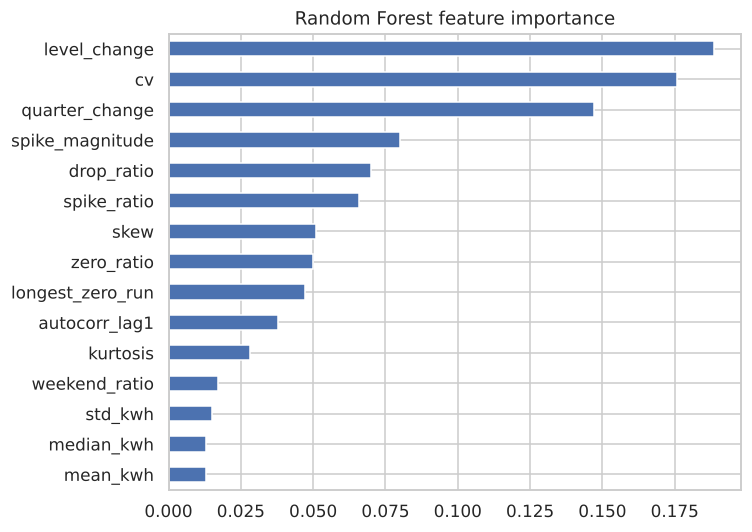

level_change       0.189
cv                 0.176
quarter_change     0.147
spike_magnitude    0.080
drop_ratio         0.070
spike_ratio        0.066
dtype: float64

In [16]:
rf_fitted = models["Random Forest"].named_steps["randomforestclassifier"]
imp = pd.Series(rf_fitted.feature_importances_, index=FEATURE_COLUMNS).sort_values()
plt.figure(figsize=(7, 5)); imp.plot.barh(color="#4C72B0")
plt.title("Random Forest feature importance"); plt.tight_layout()
plt.savefig(FIG / "feature_importance_rf.png"); plt.show()
imp.sort_values(ascending=False).head(6).round(3)

### 9. Error analysis by theft type
Overall recall can hide weak spots, so we check how many consumers of each theft type the best model catches.

In [17]:
test_meta = data.iloc[idx_test].reset_index(drop=True).copy()
test_meta["pred"] = best_pred
test_meta["proba"] = probas[best_name]
recall_by_type = (test_meta[test_meta.is_theft == 1]
                  .groupby("theft_type")
                  .apply(lambda g: pd.Series({"n": len(g), "caught": int(g.pred.sum()),
                                              "recall": g.pred.mean()})))
print(recall_by_type.round(3))
false_pos = test_meta[(test_meta.is_theft == 0) & (test_meta.pred == 1)]
print("\nFalse positives:", len(false_pos))
false_pos[["consumer_id", "proba", "zero_ratio", "level_change", "spike_ratio"]].round(3)

                 n  caught  recall
theft_type                        
bypass        11.0     8.0   0.727
intermittent  12.0    12.0   1.000
spike_drop     7.0     7.0   1.000

False positives: 5


,consumer_id,proba,zero_ratio,level_change,spike_ratio
73,C0154,0.591,0.0,0.818,0.055
104,C0263,0.736,0.0,0.894,0.044
121,C0823,0.684,0.0,0.724,0.041
166,C0846,0.537,0.0,0.871,0.036
194,C0664,0.876,0.0,0.807,0.038


### 10. Results summary and model selection
We save the cross-validation and test results, then choose a production model by F1 on the test set, weighted with ROC-AUC. The tuned Random Forest is kept if it beats the best default model.

In [18]:
out = ROOT / "outputs"
cv_df.to_csv(out / "cv_results.csv")
test_df.to_csv(out / "test_results.csv")
recall_by_type.to_csv(out / "recall_by_theft_type.csv")
imp.sort_values(ascending=False).to_csv(out / "feature_importance_rf.csv", header=["importance"])

tuned_f1 = precision_recall_fscore_support(y_test, tp, average="binary", zero_division=0)[2]
best_f1 = test_df.loc[best_name, "f1"]
if tuned_f1 >= best_f1:
    final_model, final_name = tuned, "Random Forest (tuned)"
else:
    final_model, final_name = models[best_name], best_name
final_model.fit(X, y)   # refit on the full labelled dataset for deployment
joblib.dump({"model": final_model, "features": FEATURE_COLUMNS, "name": final_name},
            ROOT / "models" / "best_model.joblib")
print("Saved production model:", final_name)

Saved production model: Gradient Boosting


### 11. Working prototype: score a new consumer
The prototype scores any consumer's daily readings and returns a risk probability and a verdict. It uses the same feature code as training.

In [19]:
def detect_theft(daily_kwh, threshold=0.5):
    """Return a risk score and verdict for one consumer's daily kWh list (at least 30 days)."""
    from features import series_features
    bundle = joblib.load(ROOT / "models" / "best_model.joblib")
    feats = pd.DataFrame([series_features(np.asarray(daily_kwh, dtype=float))])[bundle["features"]]
    prob = float(bundle["model"].predict_proba(feats)[0, 1])
    return {"risk_score": round(prob, 3),
            "verdict": "SUSPECTED THEFT / ABNORMAL" if prob >= threshold else "normal"}

# Demo on one consumer of each class (rng-based sample from the data)
demo_ids = {"normal": labels[labels.theft_type == "none"].consumer_id.iloc[0]}
for t in ["bypass", "intermittent", "spike_drop"]:
    demo_ids[t] = labels[labels.theft_type == t].consumer_id.iloc[0]
for label, cid in demo_ids.items():
    series = readings.loc[readings.consumer_id == cid, "kwh"].values
    result = detect_theft(series)
    print(f"{cid} (true: {label:<13}) -> {result}")

C0001 (true: normal       ) -> {'risk_score': 0.003, 'verdict': 'normal'}
C0005 (true: bypass       ) -> {'risk_score': 0.95, 'verdict': 'SUSPECTED THEFT / ABNORMAL'}
C0031 (true: intermittent ) -> {'risk_score': 0.982, 'verdict': 'SUSPECTED THEFT / ABNORMAL'}
C0009 (true: spike_drop   ) -> {'risk_score': 0.98, 'verdict': 'SUSPECTED THEFT / ABNORMAL'}


### 12. Conclusions, limitations, and next steps
**Findings (1,000 synthetic consumers, 15% theft, 200-consumer stratified test set)**
- **Gradient Boosting** gave the best held-out result (F1 0.871, ROC-AUC 0.987, PR-AUC 0.949), with Random Forest close behind (F1 0.867). Logistic Regression had the highest cross-validated ROC-AUC (0.985), so a simple linear model is a strong, interpretable baseline. The top models are within noise of each other on 30 test thefts.
- **Level and variability features** matter most: `level_change`, `cv`, `quarter_change`, and `spike_magnitude` lead the Random Forest importances. This matches how the theft signatures were built.
- **Bypass is the hardest case.** Recall was 73% (8 of 11) versus 100% for intermittent and spike-and-drop theft. Bypass cuts consumption to 55–85% of normal, which overlaps with vacant homes and seasonal dips.
- **Isolation Forest** (no labels) reached F1 0.644 and ROC-AUC 0.892, well below the supervised models. It is weaker, but it could still flag candidates for review when no labels exist.
- **Tuning** the Random Forest with grid search raised CV F1 to 0.882, but it did not beat the default Gradient Boosting on the test set, so Gradient Boosting was kept as the production model.

**Limitations**
- The data is synthetic. Its theft and benign patterns were designed by us, so real performance will differ. Real meter data has tariffs, holidays, and faulty meters that create more false alarms.
- The test set has only 30 thefts, so one or two errors move recall by several points. Confidence intervals are wide.
- Only daily readings are used. Hourly data would expose more theft patterns.
- Labels are assumed perfect. Real utilities confirm theft only through inspections, which introduces label noise.

**Next steps**
- Validate on real utility data, with inspection outcomes as labels.
- Improve bypass detection with hourly data or household-level comparison against similar consumers.
- Choose the decision threshold from the cost ratio of inspections to lost revenue, rather than the default 0.5.
- Add temporal models (LSTM or residuals from a seasonal forecast) for trend-aware detection.